In [1]:
# Importamos las librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Generador de numeros aleatorios
np.random.seed(42)
generador = np.random.default_rng(42)

# Eje temporal
tiempo = np.linspace(0, 60, 601)
momento_accidente = 25

# Tiempo transcurrido desde el accidente
tiempo_accidente = np.maximum(tiempo - momento_accidente, 0)

# Identificar el momento del accidente
accidente_iniciado = tiempo >= momento_accidente

# POTENCIA

potencia_normal = (
    80
    + 2 * np.sin(tiempo / 4)
    + 1.2 * np.sin(tiempo / 1.7)
    + generador.normal(0, 0.5, len(tiempo))
)

potencia_accidente = np.where(
    accidente_iniciado,
    potencia_normal
    + 12 * (1 - np.exp(-tiempo_accidente / 3))
    + 65 * (1 - np.exp(-tiempo_accidente / 15))
    + 5 * np.sin(tiempo_accidente / 2)
    + generador.normal(0, 1.5, len(tiempo)),
    potencia_normal
)

potencia_accidente = np.clip(potencia_accidente, 70, 160)


# TEMPERATURA


temperatura_normal = (
    280
    + 3 * np.sin(tiempo / 5)
    + 1.5 * np.sin(tiempo / 1.8)
    + generador.normal(0, 0.8, len(tiempo))
)

temperatura_accidente = np.where(
    accidente_iniciado,
    temperatura_normal
    + 650 * (1 - np.exp(-tiempo_accidente / 16))
    + 18 * np.sin(tiempo_accidente / 2.5)
    + 8 * np.sin(tiempo_accidente / 0.9)
    + generador.normal(0, 5, len(tiempo)),
    temperatura_normal
)

temperatura_accidente = np.clip(temperatura_accidente, 270, 950)

# REFRIGERACION

refrigeracion_normal = (
    99
    + 0.8 * np.sin(tiempo / 6)
    + 0.4 * np.sin(tiempo / 2)
    + generador.normal(0, 0.15, len(tiempo))
)

refrigeracion_accidente = np.where(
    accidente_iniciado,
    refrigeracion_normal
    - 89 * (1 - np.exp(-tiempo_accidente / 13))
    + 3 * np.sin(tiempo_accidente / 2)
    + generador.normal(0, 1.2, len(tiempo)),
    refrigeracion_normal
)

refrigeracion_normal = np.clip(refrigeracion_normal, 0, 100)
refrigeracion_accidente = np.clip(refrigeracion_accidente, 5, 100)

# RIESGO

riesgo_normal = (
    3
    + 0.8 * np.sin(tiempo / 8)
    + generador.normal(0, 0.15, len(tiempo))
)

riesgo_accidente = 100 / (
    1 + np.exp(
        -(
            0.018 * (temperatura_accidente - 500)
            + 0.045 * (65 - refrigeracion_accidente)
        )
    )
)

# DATAFRAME

datos_accidente = pd.DataFrame({
    "Potencia": potencia_accidente,
    "Temperatura": temperatura_accidente,
    "Refrigeracion": refrigeracion_accidente,
    "Riesgo": riesgo_accidente
})

# Mostrar los primeros registros
datos_accidente.head()

,Potencia,Temperatura,Refrigeracion,Riesgo
0,80.152359,280.336181,98.870109,0.415987
1,79.600550,280.061369,98.786200,0.415502
2,80.616035,279.765841,99.110205,0.407349
3,80.830809,279.889366,99.046570,0.409418
4,79.503904,280.000471,98.776932,0.415221


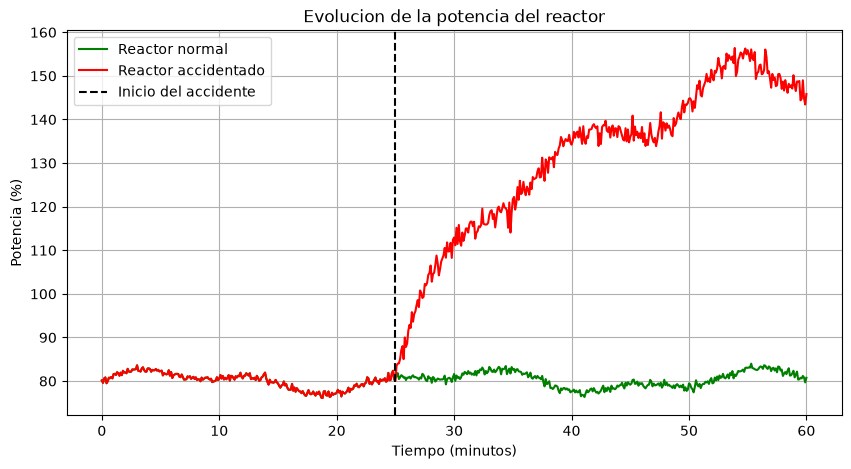

In [2]:
plt.figure(figsize=(10, 5))

plt.plot(
    tiempo,
    potencia_normal,
    label="Reactor normal",
    color="green"
)

plt.plot(
    tiempo,
    potencia_accidente,
    label="Reactor accidentado",
    color="red"
)

plt.axvline(
    momento_accidente,
    color="black",
    linestyle="--",
    label="Inicio del accidente"
)

plt.title("Evolucion de la potencia del reactor")
plt.xlabel("Tiempo (minutos)")
plt.ylabel("Potencia (%)")
plt.grid(True)
plt.legend()

plt.show()

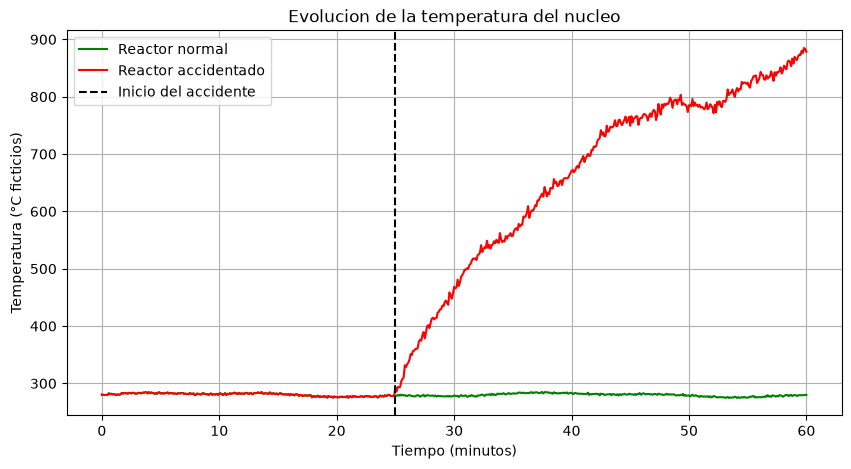

In [3]:
plt.figure(figsize=(10, 5))

plt.plot(
    tiempo,
    temperatura_normal,
    label="Reactor normal",
    color="green"
)

plt.plot(
    tiempo,
    temperatura_accidente,
    label="Reactor accidentado",
    color="red"
)

plt.axvline(
    momento_accidente,
    color="black",
    linestyle="--",
    label="Inicio del accidente"
)

plt.title("Evolucion de la temperatura del nucleo")
plt.xlabel("Tiempo (minutos)")
plt.ylabel("Temperatura (°C ficticios)")
plt.grid(True)
plt.legend()

plt.show()

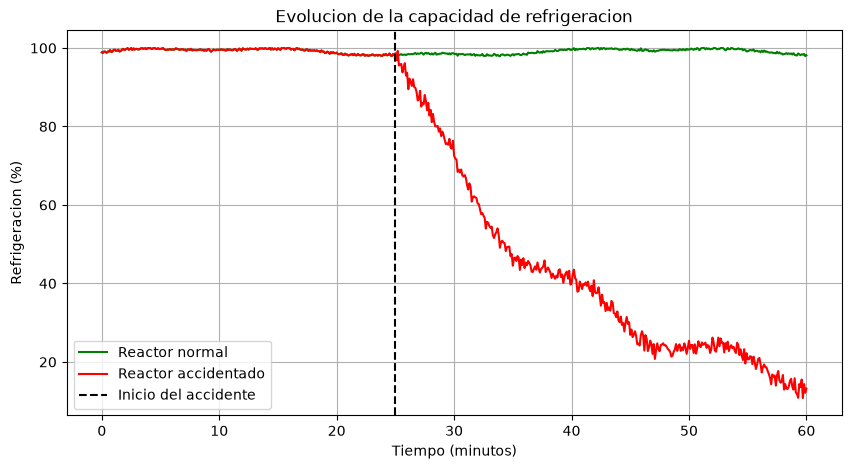

In [4]:
plt.figure(figsize=(10, 5))

plt.plot(
    tiempo,
    refrigeracion_normal,
    label="Reactor normal",
    color="green"
)

plt.plot(
    tiempo,
    refrigeracion_accidente,
    label="Reactor accidentado",
    color="red"
)

plt.axvline(
    momento_accidente,
    color="black",
    linestyle="--",
    label="Inicio del accidente"
)

plt.title("Evolucion de la capacidad de refrigeracion")
plt.xlabel("Tiempo (minutos)")
plt.ylabel("Refrigeracion (%)")
plt.grid(True)
plt.legend()

plt.show()

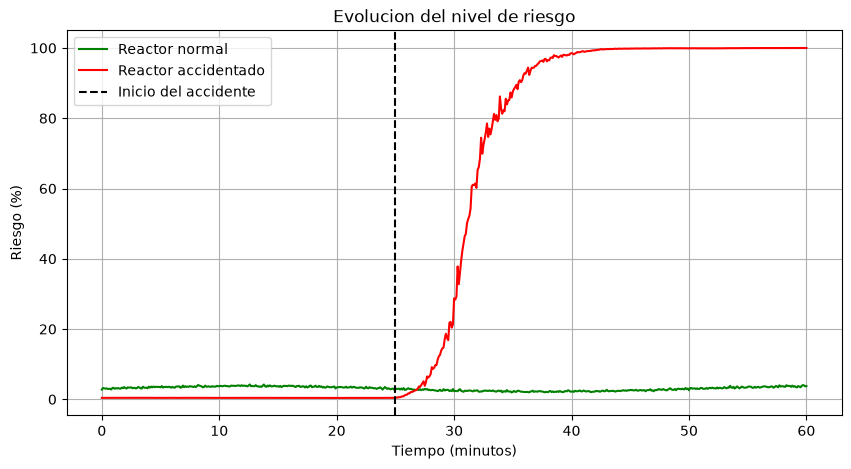

In [5]:
plt.figure(figsize=(10, 5))

plt.plot(
    tiempo,
    riesgo_normal,
    label="Reactor normal",
    color="green"
)

plt.plot(
    tiempo,
    riesgo_accidente,
    label="Reactor accidentado",
    color="red"
)

plt.axvline(
    momento_accidente,
    color="black",
    linestyle="--",
    label="Inicio del accidente"
)

plt.title("Evolucion del nivel de riesgo")
plt.xlabel("Tiempo (minutos)")
plt.ylabel("Riesgo (%)")
plt.grid(True)
plt.legend()

plt.show()

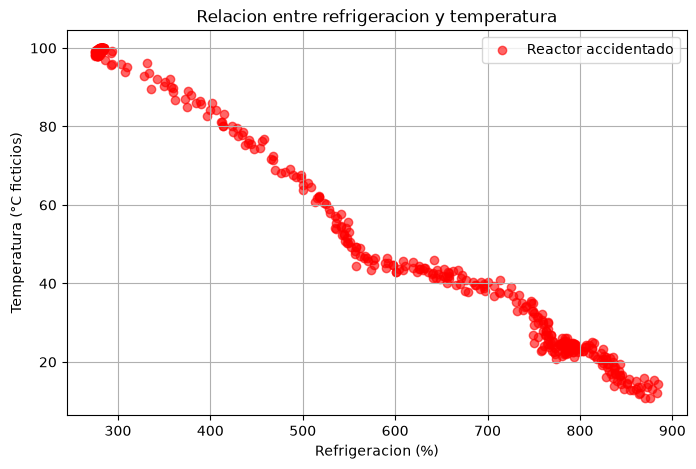

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(
    temperatura_accidente,
    refrigeracion_accidente,
    color="red",
    label="Reactor accidentado",
    alpha=0.6
)

plt.title("Relacion entre refrigeracion y temperatura")
plt.xlabel("Refrigeracion (%)")
plt.ylabel("Temperatura (°C ficticios)")
plt.grid(True)
plt.legend()

plt.show()

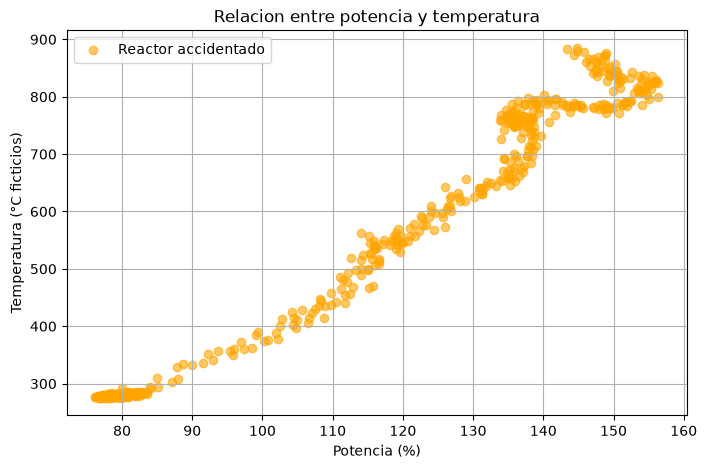

In [8]:
plt.figure(figsize=(8, 5))

plt.scatter(
    potencia_accidente,
    temperatura_accidente,
    color="orange",
    label="Reactor accidentado",
    alpha=0.6
)

plt.title("Relacion entre potencia y temperatura")
plt.xlabel("Potencia (%)")
plt.ylabel("Temperatura (°C ficticios)")
plt.grid(True)
plt.legend()

plt.show()

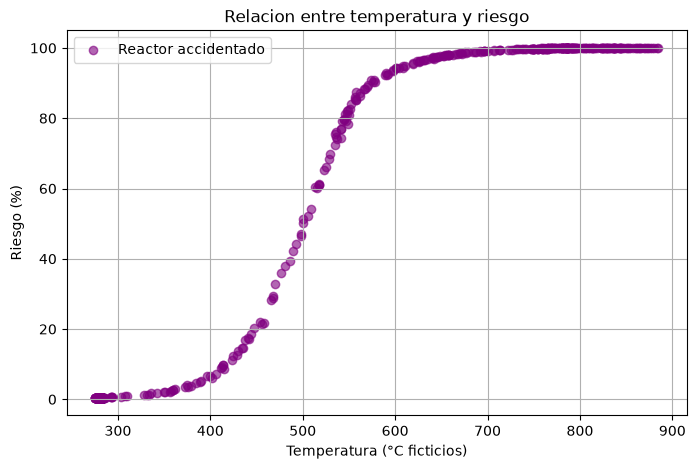

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(
    temperatura_accidente,
    riesgo_accidente,
    color="purple",
    label="Reactor accidentado",
    alpha=0.6
)

plt.title("Relacion entre temperatura y riesgo")
plt.xlabel("Temperatura (°C ficticios)")
plt.ylabel("Riesgo (%)")
plt.grid(True)
plt.legend()

plt.show()

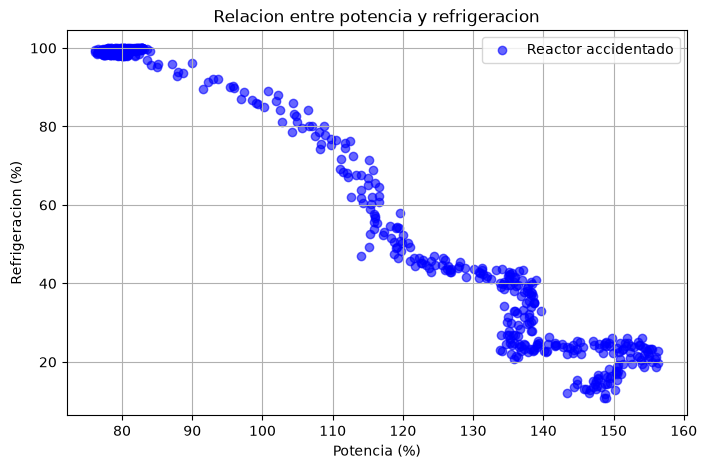

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(
    potencia_accidente,
    refrigeracion_accidente,
    color="blue",
    label="Reactor accidentado",
    alpha=0.6
)

plt.title("Relacion entre potencia y refrigeracion")
plt.xlabel("Potencia (%)")
plt.ylabel("Refrigeracion (%)")
plt.grid(True)
plt.legend()

plt.show()

In [ ]:
# Calcular la matriz de correlacion
matriz_correlacion = datos_accidente.corr()

# Crear la grafica
plt.figure(figsize=(8, 6))

plt.imshow(
    matriz_correlacion,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

# Añadir etiquetas
plt.xticks(
    range(len(matriz_correlacion.columns)),
    matriz_correlacion.columns,
    rotation=45
)

plt.yticks(
    range(len(matriz_correlacion.columns)),
    matriz_correlacion.columns
)

# Añadir los valores numericos
for i in range(len(matriz_correlacion.columns)):
    for j in range(len(matriz_correlacion.columns)):
        plt.text(
            j,
            i,
            f"{matriz_correlacion.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            color="black"
        )

plt.colorbar(label="Correlacion")
plt.title("Matriz de correlacion de las variables")
plt.tight_layout()

plt.show()